Local noise learning uses `qiskit-noise-learning` with `AerExecutor`. Run the installation cell once, then restart the kernel if needed and run the remaining cells in order. The alpha package is pinned to a specific revision for reproducibility.

The toy and Ising experiments learn explicitly injected synthetic noise; they do not characterize the fake backend's calibration noise. No cloud job IDs or IBM Quantum credentials are required. Local results are converted with `to_dict()`.

Reference: [Qiskit local noise-learning tutorial](https://github.com/Qiskit/qiskit-noise-learning/blob/main/docs/tutorials/noise_learner.md).

%pip install "git+https://github.com/Qiskit/qiskit-noise-learning@22c85a7681b3491b857460d068993f22dfb572ac"


In [15]:
import numpy as np
import matplotlib.pyplot as plt 
from matplotlib.patches import Patch 

from IPython.display import display 

from qiskit import QuantumCircuit 
from qiskit.quantum_info import Pauli, SparsePauliOp, PauliLindbladMap
from qiskit.transpiler import generate_preset_pass_manager

from qiskit_ibm_runtime import QuantumProgram
from qiskit_ibm_runtime.options import EstimatorOptions
from qiskit_ibm_runtime.fake_provider import *


# Samplomatic
import samplomatic
from samplomatic import Twirl, InjectNoise, ChangeBasis, build
from samplomatic.transpiler import generate_boxing_pass_manager 
from samplomatic.utils import find_unique_box_instructions, get_annotation


# qiskit addons 
from qiskit_addon_utils.exp_vals.measurement_bases import get_measurement_bases
from qiskit_addon_utils.exp_vals.expectation_values import executor_expectation_values
from qiskit_addon_utils.noise_management import trex_factors, gamma_from_noisy_boxes
from qiskit_addon_pna import generate_noise_mitigating_observable
from qiskit_addon_slc.bounds import compute_backward_bounds, compute_forward_bounds, compute_local_scales, merge_bounds
from qiskit_addon_slc.utils import generate_noise_model_paulis, map_modifier_ref_to_ref
from qiskit_addon_slc.visualization import draw_shaded_lightcone
# Local learner and simulator (not the Runtime NoiseLearner).
from qiskit_aer import AerSimulator
from qiskit_noise_learning.aer_executor import AerExecutor
from qiskit_noise_learning.noise_learner import LearningOptions, NoiseLearner

from qiskit.quantum_info import PauliLindbladMap
from samplomatic.annotations import InjectNoise
from samplomatic.utils import get_annotation

from qiskit_aer import AerSimulator
from qiskit_noise_learning.aer_executor import AerExecutor
from qiskit_noise_learning.noise_learner import LearningOptions, NoiseLearner

In [16]:
from qiskit.circuit import BoxOp, CircuitInstruction

def synthetic_noise_dict(unique_layers, seed: int = 42,
                         mean_rate_1q: float = 2e-3, 
                         mean_rate_2q: float = 1e-2,
                         mean_spam_rate: float = 1e-2) -> dict[str, PauliLindbladMap]:
    rng = np.random.default_rng(seed)
    noise_dict = {}

    # Collect all active physical Qubit objects across all layers in ascending index order
    all_qubits = sorted(
        {q for inst in unique_layers for q in inst.qubits if q._index is not None},
        key=lambda q: q._index,
    )
    all_active_qubits = {q._index for q in all_qubits}

    for idx, inst in enumerate(unique_layers):
        # Pad partial-width boxes in-place to span all_qubits so local NoiseLearner.run()
        # sees uniform box widths across all layers without needing a loop in the caller cell.
        if len(inst.qubits) < len(all_qubits):
            old_body = inst.operation.body
            q_map = [all_qubits.index(q) for q in inst.qubits]
            new_body = QuantumCircuit(len(all_qubits), old_body.num_clbits)
            new_body.compose(
                old_body,
                qubits=q_map,
                clbits=list(range(old_body.num_clbits)),
                inplace=True,
            )
            new_box = BoxOp(new_body, annotations=inst.operation.annotations)
            inst = CircuitInstruction(new_box, tuple(all_qubits), inst.clbits)
            unique_layers[idx] = inst

        # print("this is instance \n",inst)
        # print("**"*50)
        # print(f"Layer {inst.operation.name}:")
        # print("--"*50)
        # print(InjectNoise)
        
        inj_ann = get_annotation(inst.operation, InjectNoise)
        #print("this is the inject noise annotation \n",inj_ann)
        if inj_ann is None:
            continue
        tag_ref = inj_ann.ref
        #print(f"  InjectNoise.ref = {tag_ref}")

        # EXTRACT THE PHYSICAL QUBITS
        #print("\n following are the physical qubits: ", inst.qubits)
        #print("\n following are the physical qubits indices: ", [q._index for q in inst.qubits])
        num_layer_qubits = len(inst.qubits)
        # print(f"  Number of qubits in this layer: {num_layer_qubits}")

        sparse_terms = []

        # Add 1Q Pauli-Lindbald rates on each local qubit index
        for local_i in range(num_layer_qubits):
            for pauli in ("X", "Y", "Z"):
                r1 = float(rng.uniform(0.5 * mean_rate_1q, 1.5 * mean_rate_1q))
                #print("......."*50)
                #print(f"  Adding 1Q {pauli} rate {r1:.3e} on qubit {local_i}")
                sparse_terms.append((pauli, [local_i], r1))
        #print(f"SPARSE_TERMS:{sparse_terms}")
        
        #  INSPECT INSIDE THE BOXOP BODY TO ADD 2Q PAULI-LINDBALD
        box_circuit = inst.operation.body
        #print(box_circuit)
        #print(box_circuit.data)
        for sub_inst in box_circuit.data:
            #print("sub_inst: ",sub_inst)
            if len(sub_inst.qubits)==2:
                
                # local indices inside box-circuit match inst.qubits position
                l0 = box_circuit.find_bit(sub_inst.qubits[0]).index
                l1 = box_circuit.find_bit(sub_inst.qubits[1]).index
                #print(f"l0: {l0}")
                #print(f"l1: {l1}")

                for pauli_2q, scale in [("ZZ", 1), ("XX", 0.5), ("YY", 0.5), ("IZ", 0.5), ("ZI", 0.5)]:
                    r2 = float(rng.uniform(0.5*mean_rate_2q, 1.5*mean_rate_2q)*scale)
                    #print(f"  Adding 2Q {pauli_2q} rate {r2:.3e} on qubit {l0} and {l1}")
                    sparse_terms.append((pauli_2q, [l0, l1], r2))
        noise_dict[tag_ref] = PauliLindbladMap.from_sparse_list(
                    sparse_terms, num_qubits=num_layer_qubits
        )

    # SPAM NOISE FOR AEREXECUTOR'S ACTIVE LEARNING QUBITS
    num_active = len(all_active_qubits)
    if num_active > 0:
        p_terms = [("X", [i], float(rng.uniform(0.5*mean_spam_rate, 1.5*mean_spam_rate))) for i in range(num_active)]
        m_terms = [("X", [i], float(rng.uniform(0.5*mean_spam_rate, 1.5*mean_spam_rate))) for i in range(num_active)]
        noise_dict["P"] = PauliLindbladMap.from_sparse_list(p_terms, num_qubits=num_active)
        noise_dict["M"] = PauliLindbladMap.from_sparse_list(m_terms, num_qubits=num_active)
        #print(f"  Active qubits so far: {sorted(all_active_qubits)}")
        #print("--end**"*50)
    #print(noise_dict)
    return noise_dict

In [17]:
from samplomatic.annotations import InjectNoise 
from samplomatic.utils import get_annotation

def local_result_to_dict(noise_result, unique_layers):
    """ 
    Local equivalent of NoiseLearnerV3Results.to_dict(unique_layers, unique_refs=False)
    Slices the 156-qubit global PauliLindbaldMap down to the exact local qubits of each box.
    """
    # Local qiskit_noise_learning.to_dict() takes no arguements and returns 156-qubit maps
    global_noise_dict = noise_result.to_dict()
    #print(f"Global Noise Dict: {global_noise_dict}")

    refs_to_noise = {}
    for inst in unique_layers:
        #print(f"\n Unique Layer: {inst}")
        #print(f"\n Instance Operation: {inst.operation}")
        #print(f"\n NoiseInjection: {InjectNoise}")
        inj_ann = get_annotation(inst.operation, InjectNoise)
        #print(f"\n NOISE INJECTED: {inj_ann}")
        if inj_ann is None: 
            continue
        ref = inj_ann.ref
        #print(f"\n Injected Noise reference: {ref}")

        if ref in global_noise_dict:
            global_map = global_noise_dict[ref]
            #print("-------INNER LOOP-------------------------------")
            #print(f"\n Global Map: {global_map}")
            # Extract physical qubit indices for the active gates in this specific box
            box_body = inst.operation.body
            active_local_idxs = sorted(
                {
                    box_body.find_bit(q).index
                    for sub in box_body.data
                    if sub.operation.name != "noop"
                    for q in sub.qubits
                }
            )
            if active_local_idxs:
                phys_qubits = [inst.qubits[i]._index for i in active_local_idxs]
            else:
                phys_qubits = [q._index for q in inst.qubits]
            #print(f"\n Physical qubits: {phys_qubits}")

            # If the map is 156-qubit global, slice it down to the 2 local qubits of the box
            if global_map.num_qubits > len(phys_qubits):
                refs_to_noise[ref] = global_map.keep_qubits(phys_qubits)
            else:
                refs_to_noise[ref] = global_map
        #print("---"*50)
    return refs_to_noise

In [18]:
def construct_ising_circuit(num_qubits: int, num_trotter_steps: int, rx_angle: float, barrier: bool = True) ->QuantumCircuit:
    """Construct a Trotterized Ising Hamiltonian circuit with transverse field.

    Args:
        num_qubits: Number of qubits in the chain.
        num_trotter_steps: Number of Trotter steps to apply.
        rx_angle: Rotation angle for the transverse field (X rotations).
        barrier: Whether to insert barriers between Trotter steps.

    Returns:
        A QuantumCircuit implementing the Trotterized Ising Hamiltonian.
    """
    qc = QuantumCircuit(num_qubits)
    for _ in range(num_trotter_steps):
        qc.rx(rx_angle, range(num_qubits))
        if barrier:
            qc.barrier()
        #for first_qubit in (1,2,3):
            #for idx in range(first_qubit, num_qubits, 3):
        # for first_qubit in (1,2):
        #     for idx in range(first_qubit, num_qubits, 2):
        #         qc.sdg([idx - 1, idx])
        #         qc.cz(idx - 1, idx)
        for idx in range(1,num_qubits):
            qc.sdg([idx - 1, idx])
            qc.cz(idx - 1, idx)
        if barrier:
            qc.barrier()

    return qc


In [19]:
backend = FakeMarrakesh()
# backend = backend.least_busy(
#     operational=True,
#     filters=lambda b: b.processor_type.get('family') == "Heron"
# )
print(f"Backend: {backend.backend_name}")
print(f"Qubits: {backend.num_qubits}")
print(f"Basis gates: {backend.basis_gates}")

isa_pm = generate_preset_pass_manager(backend=backend, optimization_level=0)

Backend: fake_marrakesh
Qubits: 156
Basis gates: ['cz', 'id', 'rz', 'sx', 'x']


In [20]:
noise_learning_boxing_pm = generate_boxing_pass_manager(
    enable_gates = True,
    enable_measures = True,
    twirling_strategy = "active",
    inject_noise_targets = "gates",
    inject_noise_strategy = "no_modification",
)

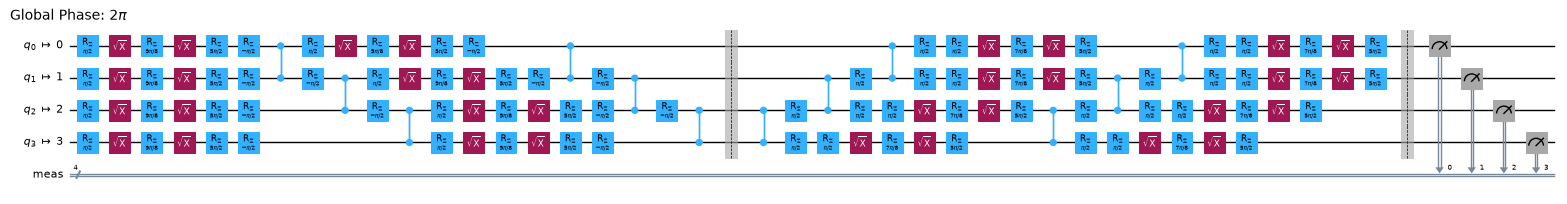

In [21]:
num_qubits = 4
ising_ex2 = None 
mirror_ex2 = None
boxed_circuit_ex2 = None

ising_ex2 = construct_ising_circuit(
    num_qubits=num_qubits,
    num_trotter_steps = 2,
    rx_angle = np.pi/8, 
    barrier = False)

mirror_ex2 = QuantumCircuit(num_qubits)
mirror_ex2.compose(ising_ex2, inplace=True)
mirror_ex2.barrier()
mirror_ex2.compose(ising_ex2.inverse(), inplace=True)
mirror_ex2.measure_all()

mirror_ex2_isa = isa_pm.run(mirror_ex2)
boxed_circuit_ex2 = noise_learning_boxing_pm.run(mirror_ex2_isa)

mirror_ex2_isa.draw("mpl", fold=-1, idle_wires=False, scale=0.5)

In [22]:
unique_layers_ex3 = find_unique_box_instructions(
    boxed_circuit_ex2,
    normalize_annotations=None,
    undress_boxes=True,)

toy_noise_dict_ex3 = synthetic_noise_dict(unique_layers_ex3)

nl_options_ex3 = LearningOptions(
    num_randomizations=5,
    shots_per_randomizations=5,
    fragment_depths=[1,2],)
aer_executor_ex3 = AerExecutor(
    AerSimulator(),
    noise_dict = toy_noise_dict_ex3,)

learner_ex3 = NoiseLearner(backend,
                           options=nl_options_ex3,
                           executor=aer_executor_ex3)

learner_job_ex3 = learner_ex3.run(unique_layers_ex3)
toy_noise_result_ex3 = learner_job_ex3.result()
print(f"Learned noise for {toy_noise_result_ex3} layer(s) locally")

Learned noise for <qiskit_noise_learning.noise_learner.noise_learner_result.NoiseLearnerResult object at 0x7f6803e06210> layer(s) locally


In [23]:
refs_to_noise_models_ex3 = local_result_to_dict(toy_noise_result_ex3, unique_layers_ex3)
print(f"Learned noise for {len(refs_to_noise_models_ex3)} layers:"
      f"{list(refs_to_noise_models_ex3.keys())}")

Learned noise for 4 layers:['r68cA', 'r45aA', 'ra79A', 'ra4bA']


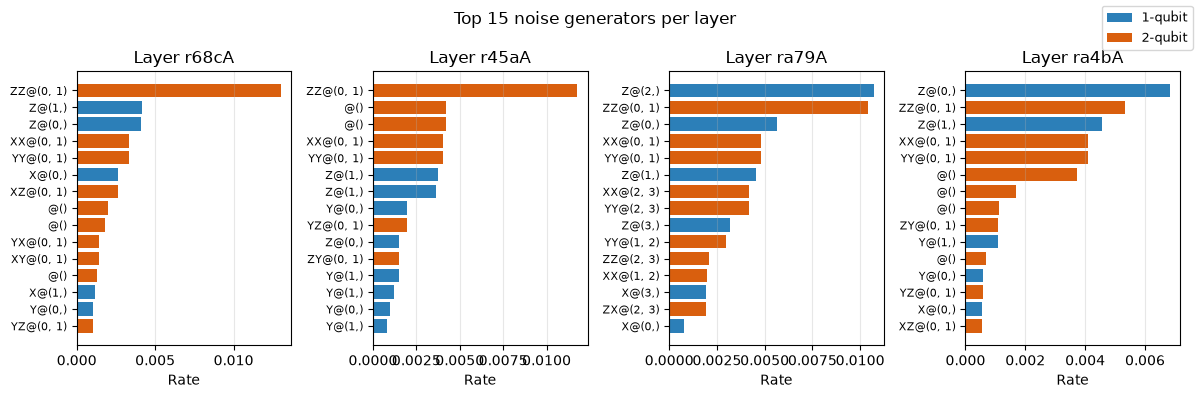

In [24]:
# plot the top 15 noise generators per layer

fig, axes = plt.subplots(1, len(refs_to_noise_models_ex3), figsize=(12,4))
if len(refs_to_noise_models_ex3)==1: axes=[axes]

for ax, (ref, plm) in zip(axes, refs_to_noise_models_ex3.items()):
    gens = sorted(plm.to_sparse_list(), key=lambda g:-abs(g[2]))[:15]
    labels = [f"{p}@{tuple(q)}" for p,q,_ in gens]
    rates = [r for _,_, r in gens]
    colors = ['#2c7fb8' if len(p) == 1 else '#d95f0e' for p, _, _ in gens]
    ax.barh(range(len(labels)), rates, color = colors)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("Rate")
    ax.set_title(f"Layer {ref}")
    ax.grid(axis="x", alpha=0.3)

fig.legend(handles=[Patch(facecolor="#2c7fb8", label="1-qubit"),
                    Patch(facecolor="#d95f0e", label="2-qubit")],
           loc="upper right", fontsize=9)
fig.suptitle("Top 15 noise generators per layer")
plt.tight_layout()
plt.show()

In [25]:
template_ex3 = None 
samplex_ex3 = None
samplex_args_ex3 = None
program_ex3 = None

# build the template and samplex from boxed_circuit_ex2
template_ex3, samplex_ex3 = build(boxed_circuit_ex2)

# inspect what the samplex expects
print(samplex_ex3.inputs())

# Bind the learned noise models into the samplex inputs.
# start from samplex_ex3.inputs(), make it broadcastable, then bind the 
# refs_to_noise_models_ex3 dict to the "pauli_lindblad_maps" arguement
samplex_args_ex3 = (
    samplex_ex3.inputs().make_broadcastable().bind(pauli_lindblad_maps=refs_to_noise_models_ex3)
)

# Assemble the quantumprogram with a single samplex item
program_ex3 = QuantumProgram(shots=64)
program_ex3.append_samplex_item(circuit=template_ex3,
                                samplex=samplex_ex3,
                                samplex_arguments=samplex_args_ex3,
                                shape=(16,))

TensorInterface(<
  - 'pauli_lindblad_maps.r45aA' <PauliLindbladMap>: A PauliLindblad map acting on 2 qubits,
      with 'num_terms_r45aA' terms.
  - 'pauli_lindblad_maps.r68cA' <PauliLindbladMap>: A PauliLindblad map acting on 2 qubits,
      with 'num_terms_r68cA' terms.
  - 'pauli_lindblad_maps.ra4bA' <PauliLindbladMap>: A PauliLindblad map acting on 2 qubits,
      with 'num_terms_ra4bA' terms.
  - 'pauli_lindblad_maps.ra79A' <PauliLindbladMap>: A PauliLindblad map acting on 4 qubits,
      with 'num_terms_ra79A' terms.
>)


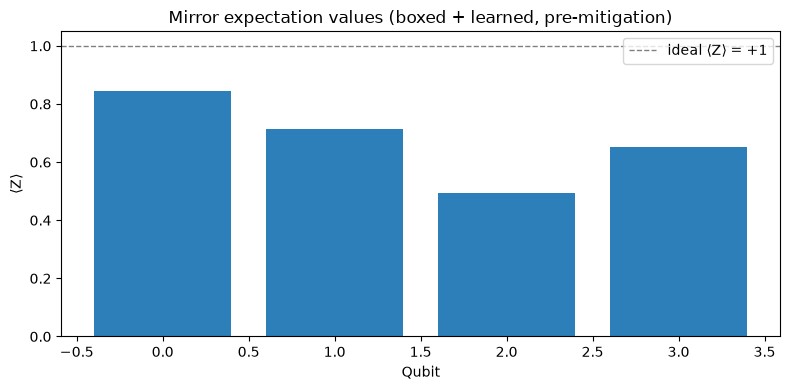

mean ⟨Z⟩ = +0.6753  (ideal = +1)


In [26]:
exec_job_ex3 = aer_executor_ex3.run(program_ex3)
exec_result_ex3 = exec_job_ex3.result()

data  = exec_result_ex3[0]
meas  = data["meas"]
flips = data["measurement_flips.meas"]

corrected = np.bitwise_xor(meas, flips)
z_vals    = 1 - 2 * corrected
z_means   = z_vals.reshape(-1, z_vals.shape[-1]).mean(axis=0)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(len(z_means)), z_means, color="#2c7fb8")
ax.axhline(1.0, color="gray", ls="--", lw=1, label="ideal ⟨Z⟩ = +1")
ax.set_xlabel("Qubit")
ax.set_ylabel("⟨Z⟩")
ax.set_ylim(0, 1.05)
ax.set_title("Mirror expectation values (boxed + learned, pre-mitigation)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"mean ⟨Z⟩ = {z_means.mean():+.4f}  (ideal = +1)")